Bounded source check: Moon–Earth terrain candidates

Follow the source-check design described below on nine preselected development
patches. This notebook reads immutable local source snapshots and downloads
nothing. Separate visible-cover evidence, estimated ground form and operational
suitability. No screen promotion, model training or reserve-region inspection.

In [7]:
import hashlib
import json
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Image, Markdown, display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from rasterio.crs import CRS
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.warp import reproject
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'outline.md').exists())
sys.path.insert(0, str(ROOT))
from notebooks.shared.inspection import file_hash
from notebooks.shared.patch_analysis import measure_patch, measure_planarity
from notebooks.shared.processing import Grid, terrain, write_raster
from notebooks.shared.retrieval_analysis import terrain_discrepancies
from notebooks.exploration.source_analysis import compare_elevation_surfaces

NOTEBOOK = ROOT / 'notebooks/exploration/24_candidate_source_check_eda.ipynb'
SAMPLE = ROOT / 'data/reference/source-check-sample-20261029'
PRIOR = ROOT / 'data/processed/analysis/candidate-inspection-20261029T132642335288Z'
SCREENING = ROOT / 'data/processed/analysis/screening-eda-20261029T091841917085Z'
SCALE = ROOT / 'data/processed/analysis/scale-eda-20261029T012946475712Z'
RAW = ROOT / 'data/raw/earth/source_checks/20261029T143533776908Z'
SOURCE_NOTE = ROOT / 'data/reference/source-check-research-20261029/SOURCES.md'
ADJUSTMENTS = ROOT / 'data/reference/source-check-research-20261029/ACQUISITION_ADJUSTMENTS.md'
OUT = ROOT / 'data/processed/analysis' / ('source-check-' + datetime.now(UTC).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True, exist_ok=False)
FEATURES = ['slope_median_deg', 'slope_p90_deg', 'central_relief_m', 'plane_residual_fraction', 'local_sd_median_m']
expected: dict[str, str] = {}
inputs: dict[str, str] = {}
for folder in [PRIOR, SCREENING, SCALE]:
    manifest = json.loads((folder / 'provenance.json').read_text())
    assert manifest['status'] == 'complete'
    inputs[str(folder / 'provenance.json')] = file_hash(folder / 'provenance.json')
    expected.update({str(Path(path).resolve()): digest for path, digest in manifest.get('inputs', {}).items()})
    expected.update({str((folder / name).resolve()): digest for name, digest in manifest['outputs'].items()})
sample_manifest = json.loads((SAMPLE / 'provenance.json').read_text())
assert sample_manifest['selection_complete']
expected.update({str((ROOT / path).resolve()): digest for path, digest in sample_manifest['inputs'].items()})
expected.update({str((SAMPLE / path).resolve()): digest for path, digest in sample_manifest['outputs'].items()})
raw_manifest = json.loads((RAW / 'manifest.json').read_text())
assert raw_manifest['status'] == 'complete'
assert file_hash(SAMPLE / 'sample.csv') == raw_manifest['sample_sha256']
for name, detail in raw_manifest['files'].items():
    path = RAW / name
    assert path.stat().st_size == detail['bytes'] and file_hash(path) == detail['sha256'], path
    inputs[str(path)] = detail['sha256']
for path in [RAW / 'manifest.json', SAMPLE / 'provenance.json', SOURCE_NOTE, ADJUSTMENTS]:
    inputs[str(path)] = file_hash(path)


def checked(path: Path) -> Path:
    key = str(path.resolve())
    if key not in inputs:
        assert key in expected, f'Unpinned input: {key}'
        assert file_hash(path) == expected[key], key
        inputs[key] = expected[key]
    return path


sample = pd.read_csv(checked(SAMPLE / 'sample.csv'))
assert len(sample) == sample['candidate_id'].nunique() == 9
grids = json.loads(checked(SCREENING / 'site_grids.json').read_text())
native = pd.read_csv(checked(PRIOR / 'native_candidate_classes.csv')).set_index('candidate_id')
previous_pairs = pd.read_csv(checked(PRIOR / 'candidate_diagnostics.csv.gz'))
lunar_metrics = pd.read_csv(checked(SCALE / 'center_metrics.csv'))
lunar_metrics['query_id'] = lunar_metrics['center_id'] + ':' + lunar_metrics['size_m'].astype(str)
lunar_lookup = lunar_metrics.loc[(lunar_metrics['body'] == 'moon') & lunar_metrics['common']].set_index('query_id', verify_integrity=True)
arcgis_records = {(r['sample_id'], r['source']): r for r in raw_manifest['records'] if 'params' in r}
landsat_records = {r['sample_id']: r for r in raw_manifest['records'] if r.get('source') == 'landsat8_c2_l2' and 'sample_id' in r}
provenance: dict[str, Any] = {'status': 'running', 'notebook': str(NOTEBOOK.relative_to(ROOT)),
    'notebook_source_sha256': hashlib.sha256('\n'.join(c.source for c in nbformat.read(NOTEBOOK, as_version=4).cells).encode()).hexdigest(),
    'raw_snapshot': str(RAW.relative_to(ROOT)), 'sample': str(SAMPLE.relative_to(ROOT)),
    'role': 'nine outcome-selected development patches; Moon and Earth only',
    'helpers': {name: file_hash(ROOT / 'notebooks' / name) for name in ['shared/inspection.py', 'shared/processing.py', 'shared/patch_analysis.py', 'shared/retrieval_analysis.py', 'exploration/source_analysis.py']},
    'software': {name: version(name) for name in ['numpy', 'pandas', 'rasterio', 'matplotlib', 'nbformat']},
    'reference_grid': '30 m exact existing UTM lattice; 150 m halo; average aggregation of 1 m export',
    'offset': 'mean(FABDEM - reference) removed per patch; not vertical datum conversion; no horizontal shift',
    'display': 'NAIP raw RGB /255; Landsat reflectance clipped to0..0.4 then gamma1/2.2; WorldCover nearest10m display',
}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))
display(sample[['sample_id', 'region', 'selection_reason', 'baseline_query_uses', 'with_planarity_query_uses']])

,sample_id,region,selection_reason,baseline_query_uses,with_planarity_query_uses
0,S01,northern_arizona,baseline_high_reuse;with_planarity_high_reuse,128,127
1,S02,northern_arizona,baseline_high_reuse,91,65
2,S03,northern_arizona,baseline_low_reuse,1,0
3,S04,northern_arizona,with_planarity_high_reuse,38,114
4,S05,northern_arizona,with_planarity_low_reuse,4,1
5,S06,atacama_san_pedro,atacama_gallery_01,0,0
6,S07,atacama_san_pedro,atacama_gallery_08,0,0
7,S08,wadi_rum,wadi_gallery_01,0,0
8,S09,wadi_rum,wadi_gallery_08,0,0


# Cover and reference-source inventory

Preserve all locked source IDs. Acquisition ranges can span several overlapping
aerial tiles. Dates in a service catalog are source evidence, not proof of
simultaneous acquisition. A 1 m export does not improve the source's resolution.

In [8]:
source_rows = []
for row in sample.to_dict('records'):
    sid = row['sample_id']
    if row['region'] == 'northern_arizona':
        for source_name in ['naip2021', 'naip2023', '3dep']:
            record = arcgis_records[(sid, source_name)]
            attrs = [item['attributes'] for item in record['selected_items']]
            if source_name.startswith('naip'):
                dates = sorted({a['Name'].split('_')[-2] for a in attrs})
                dates_text = ';'.join(dates)
            else:
                dates_text = ';'.join(sorted({f"{a['StartDate']}/{a['EndDate']}" for a in attrs}))
            source_rows.append({'sample_id': sid, 'source': source_name, 'item_ids': ';'.join(str(a['OBJECTID']) for a in attrs),
                                'item_names': ';'.join(a['Name'] for a in attrs), 'acquisition_dates': dates_text,
                                'export_resolution_m': abs(record['transform'][0]), 'valid_context_fraction': record['valid_fraction_context'],
                                'datum': ';'.join(sorted({a.get('VerticalDatum', 'not applicable') for a in attrs})),
                                'source_url': record['url'], 'source_path': record['path']})
    elif sid in landsat_records:
        record = landsat_records[sid]
        source_rows.append({'sample_id': sid, 'source': record['source'], 'item_ids': record['item_id'],
                            'item_names': record['item_id'], 'acquisition_dates': record['date'], 'export_resolution_m': 30,
                            'valid_context_fraction': None, 'datum': 'reflectance; no vertical datum',
                            'source_url': f"https://planetarycomputer.microsoft.com/api/stac/v1/collections/landsat-c2-l2/items/{record['item_id']}",
                            'source_path': record['folder']})
    else:
        source_rows.append({'sample_id': sid, 'source': 'landsat8_c2_l2', 'item_names': 'unavailable after bounded search'})
sources = pd.DataFrame(source_rows)
sources.to_csv(OUT / 'source_inventory.csv', index=False)
sample.to_csv(OUT / 'sample.csv', index=False)
display(sources[['sample_id', 'source', 'acquisition_dates', 'valid_context_fraction']])


def patch(row: dict[str, Any], channel: str) -> tuple[np.ndarray, Any, CRS]:
    path = checked(ROOT / grids[row['region']]['folder'] / f'{channel}.tif')
    with rasterio.open(path) as src:
        window = Window.from_slices((row['patch_row'], row['patch_row'] + 20), (row['patch_col'], row['patch_col'] + 20))
        transform = src.window_transform(window)
        assert src.crs is not None
        np.testing.assert_allclose(window_bounds(window, src.transform), [row['xmin'], row['ymin'], row['xmax'], row['ymax']], atol=1e-6, rtol=0)
        values = src.read(1, window=window, masked=True).astype('float64').filled(np.nan)
        assert values.shape == (20, 20) and np.isfinite(values).all()
        return values, transform, src.crs


def worldcover_display(row: dict[str, Any]) -> np.ndarray:
    path = checked(ROOT / native.loc[row['candidate_id'], 'native_source'])
    destination = np.zeros((60, 60), dtype='uint8')
    with rasterio.open(path) as src:
        reproject(rasterio.band(src, 1), destination, src_transform=src.transform, src_crs=src.crs,
                  dst_transform=from_origin(row['xmin'], row['ymax'], 10, 10), dst_crs=row['epsg'],
                  resampling=Resampling.nearest, src_nodata=0, dst_nodata=0)
    return destination


def save_figure(figure: Any, stem: str) -> None:
    figure.savefig(OUT / f'{stem}.png', dpi=140)
    figure.savefig(OUT / f'{stem}.pdf')
    plt.close(figure)
    display(Image(filename=str(OUT / f'{stem}.png')))


CLASS_CODES = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
CLASS_COLORS = ['#202020', '#006400', '#ffbb22', '#ffff4c', '#f096ff', '#fa0000', '#b4b4b4', '#f0f0f0', '#0064c8', '#0096a0', '#00cf75', '#fae6a0']
class_cmap = ListedColormap(CLASS_COLORS)
terrain_rows = []
sensitivity_rows = []
reference_features: dict[str, dict[str, float]] = {}

,sample_id,source,acquisition_dates,valid_context_fraction
0,S01,naip2021,20211015,1.0
1,S01,naip2023,20230714,1.0
2,S01,3dep,20220628/20221011,1.0
3,S02,naip2021,20211108,1.0
4,S02,naip2023,20230714,1.0
5,S02,3dep,20190816/20190820,1.0
6,S03,naip2021,20211015,1.0
7,S03,naip2023,20230714,1.0
8,S03,3dep,20230528/20230916,1.0
9,S04,naip2021,20211108,1.0


# Arizona: fixed-grid terrain and dated aerial observations

Reference selection uses the finest primary inventory resolution, then the
latest acquisition-start date among that resolution, retaining all intersecting
tiles from that acquisition. Locked rasters are ordered by ID. Coverage is checked
after export; no older fill is silently added. No horizontal registration fitting
or vertical datum transformation is performed.

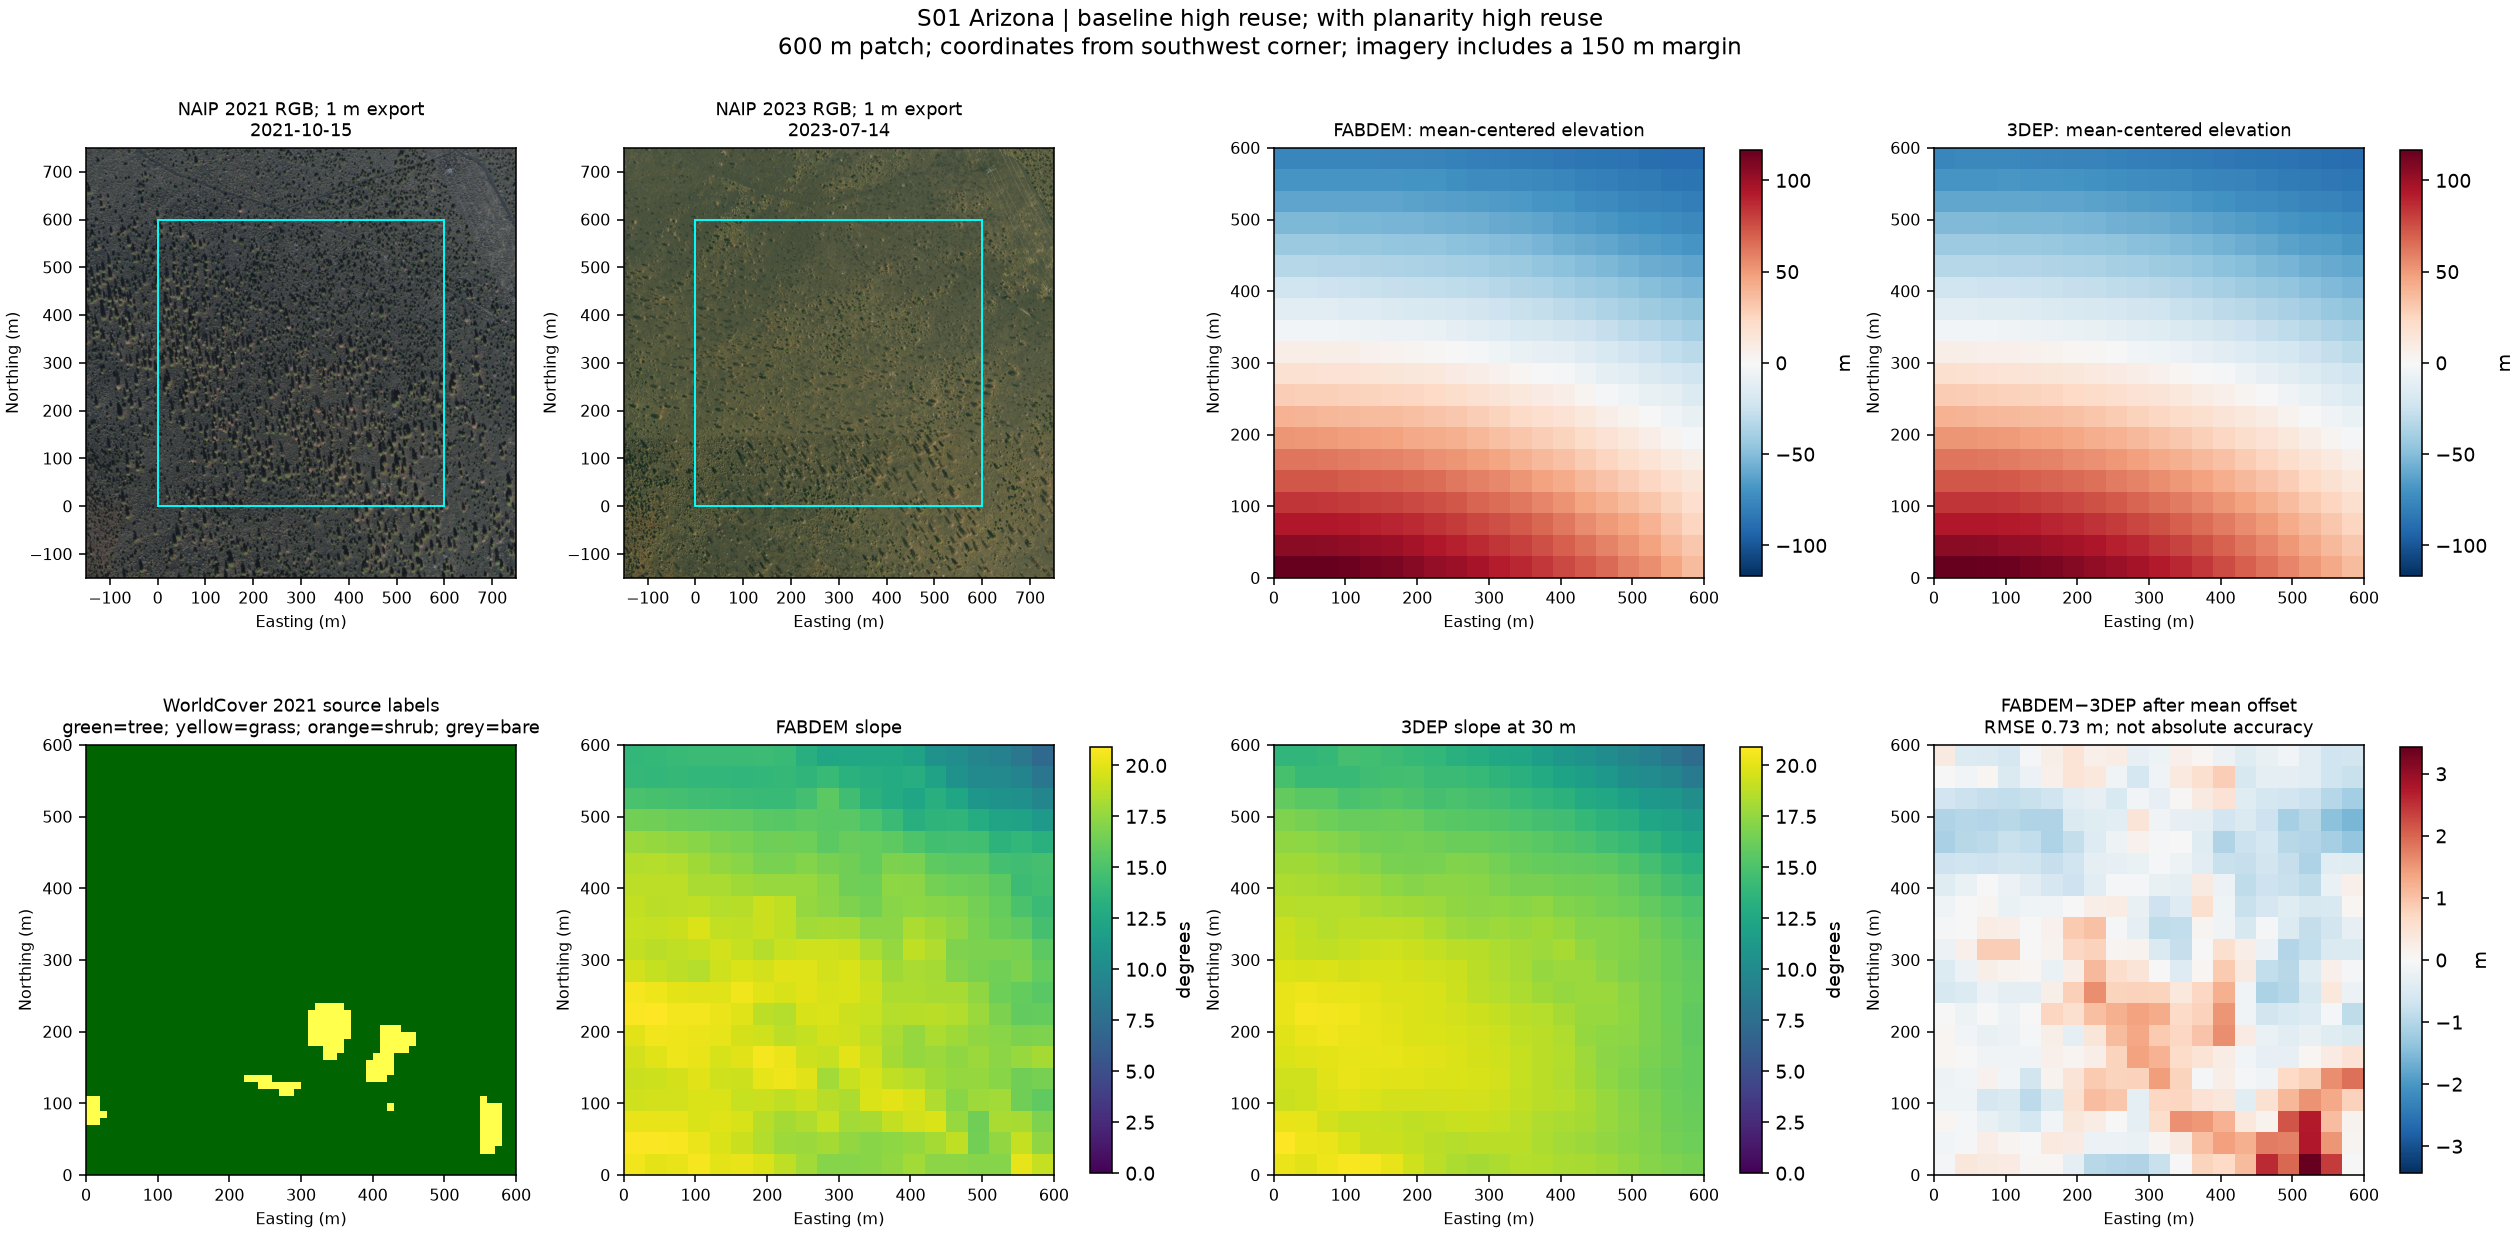

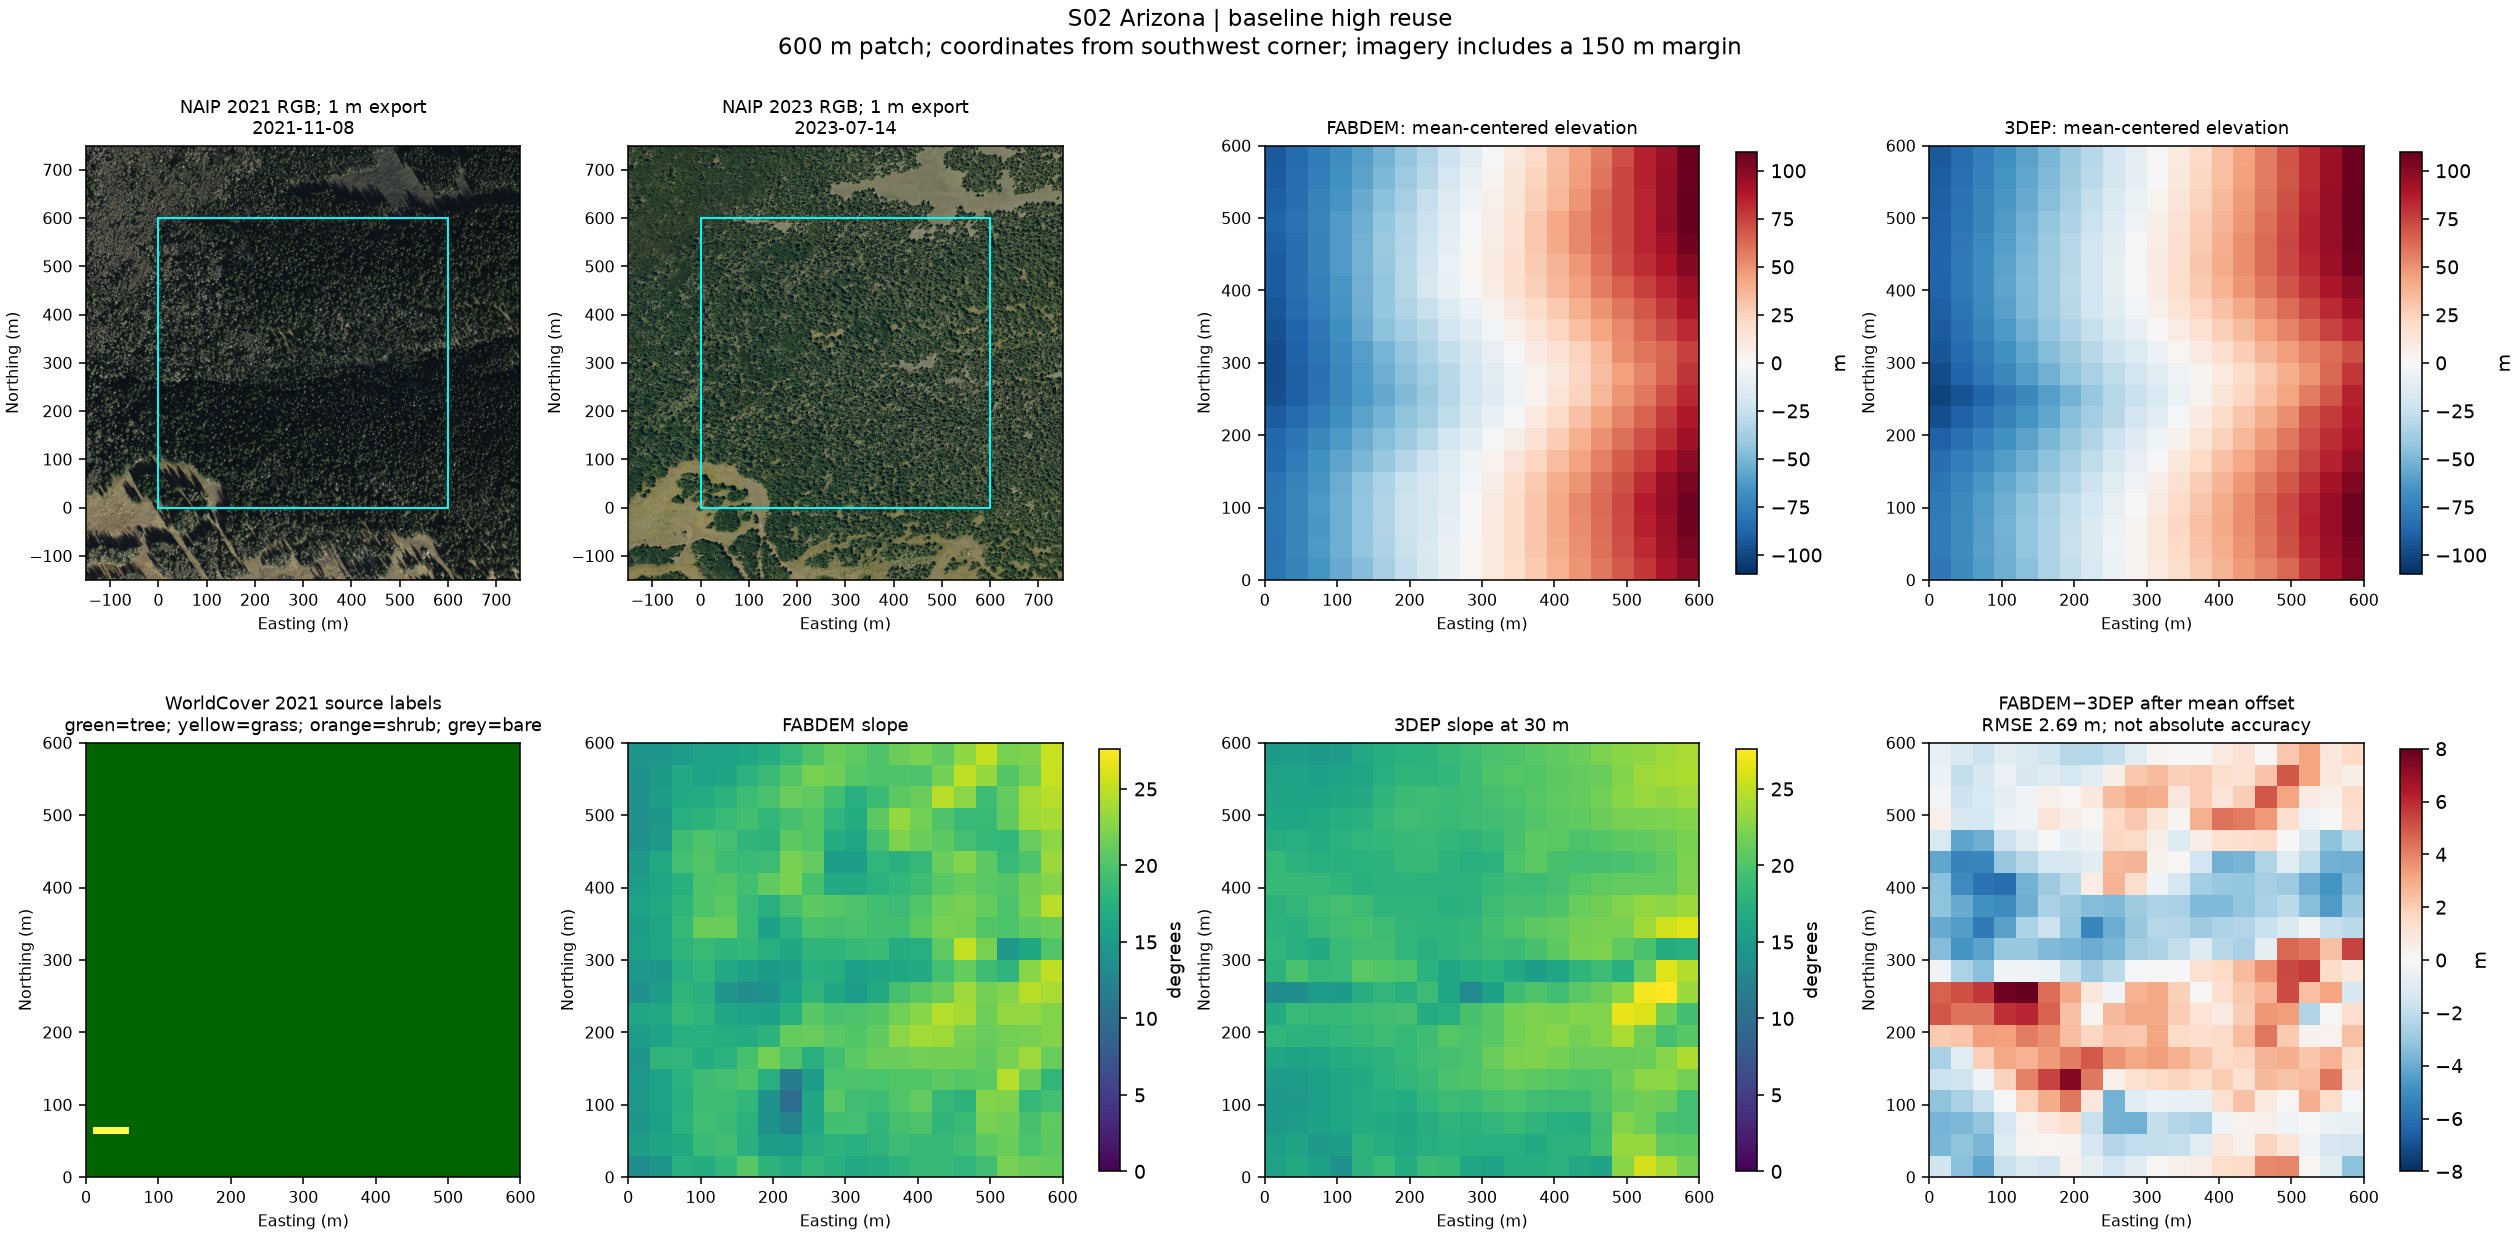

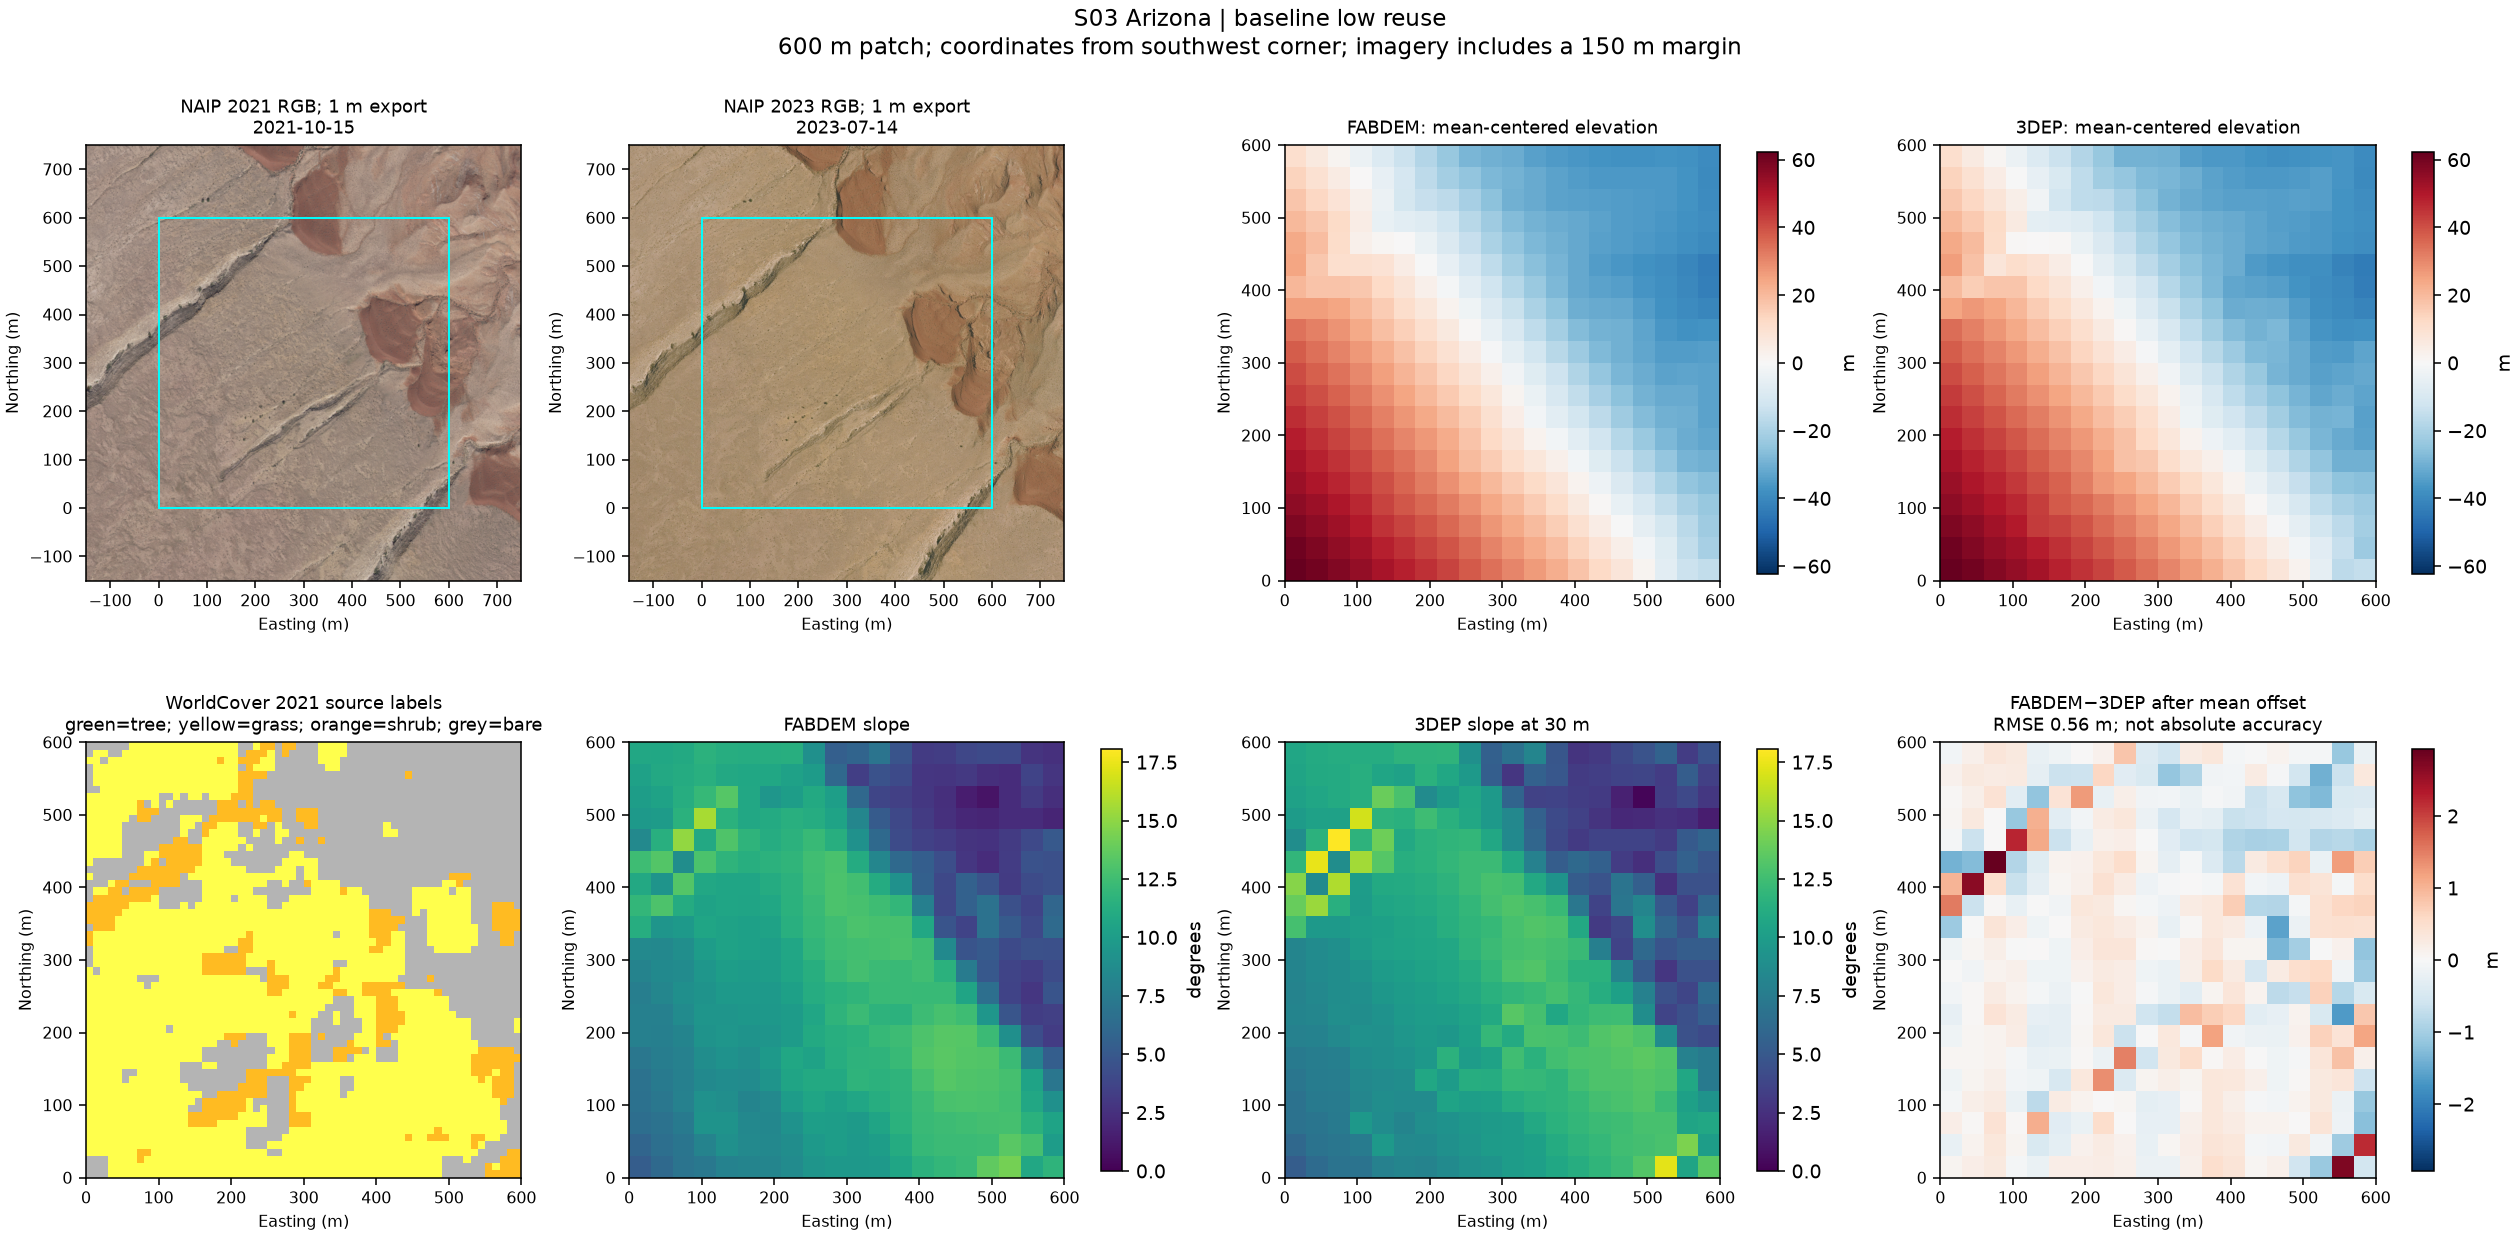

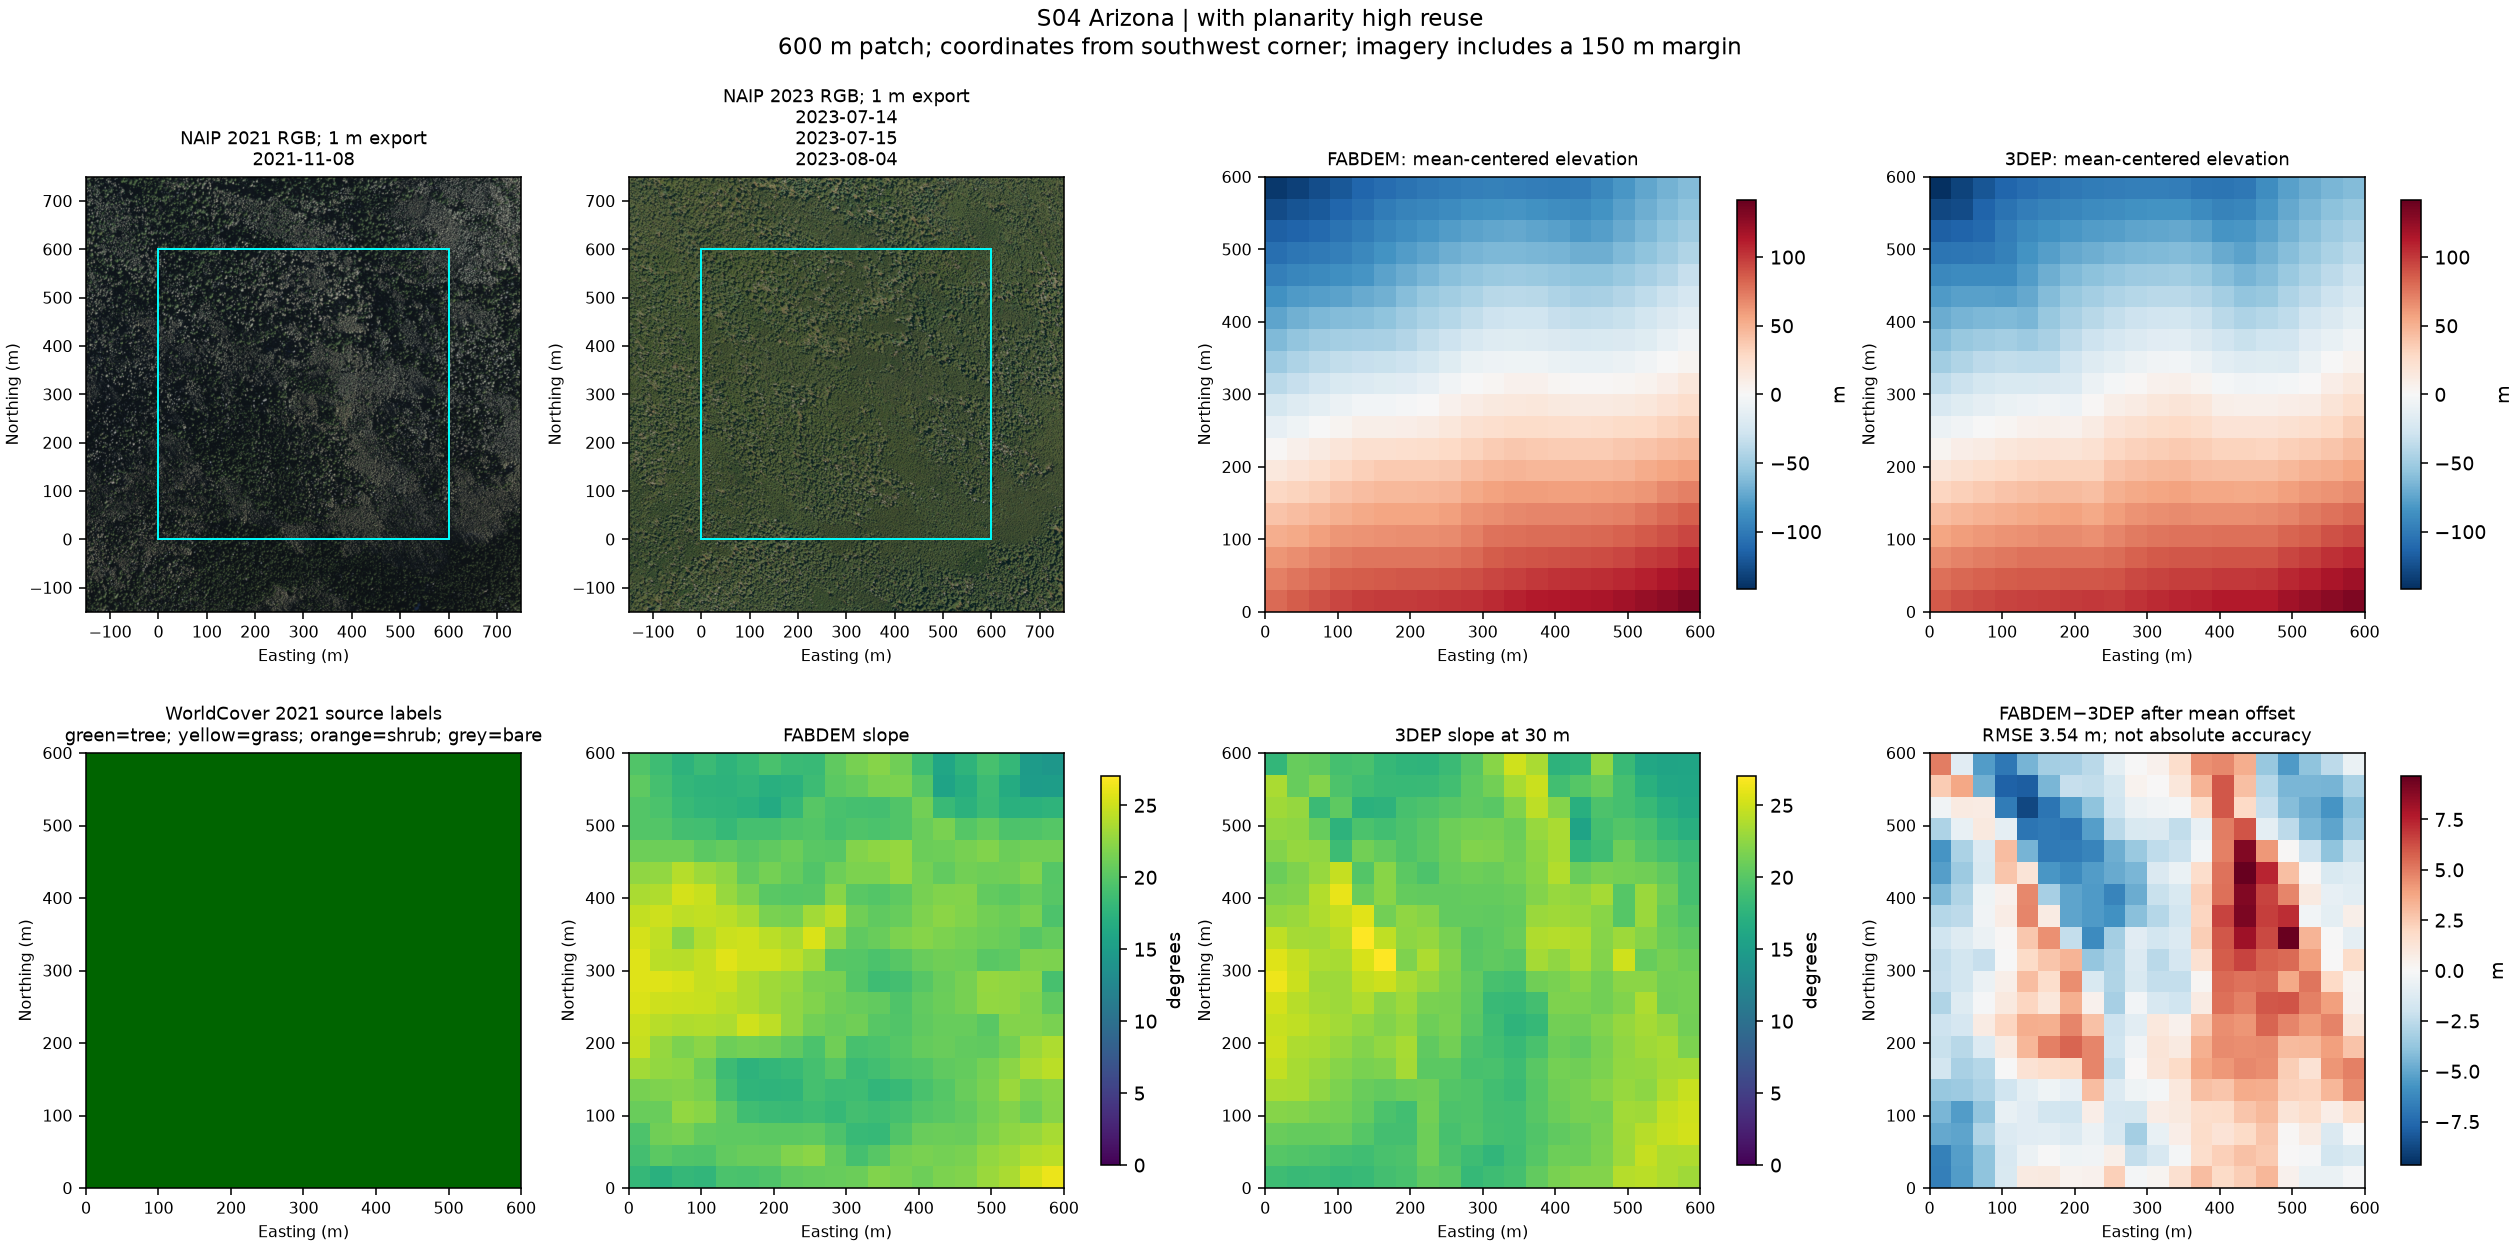

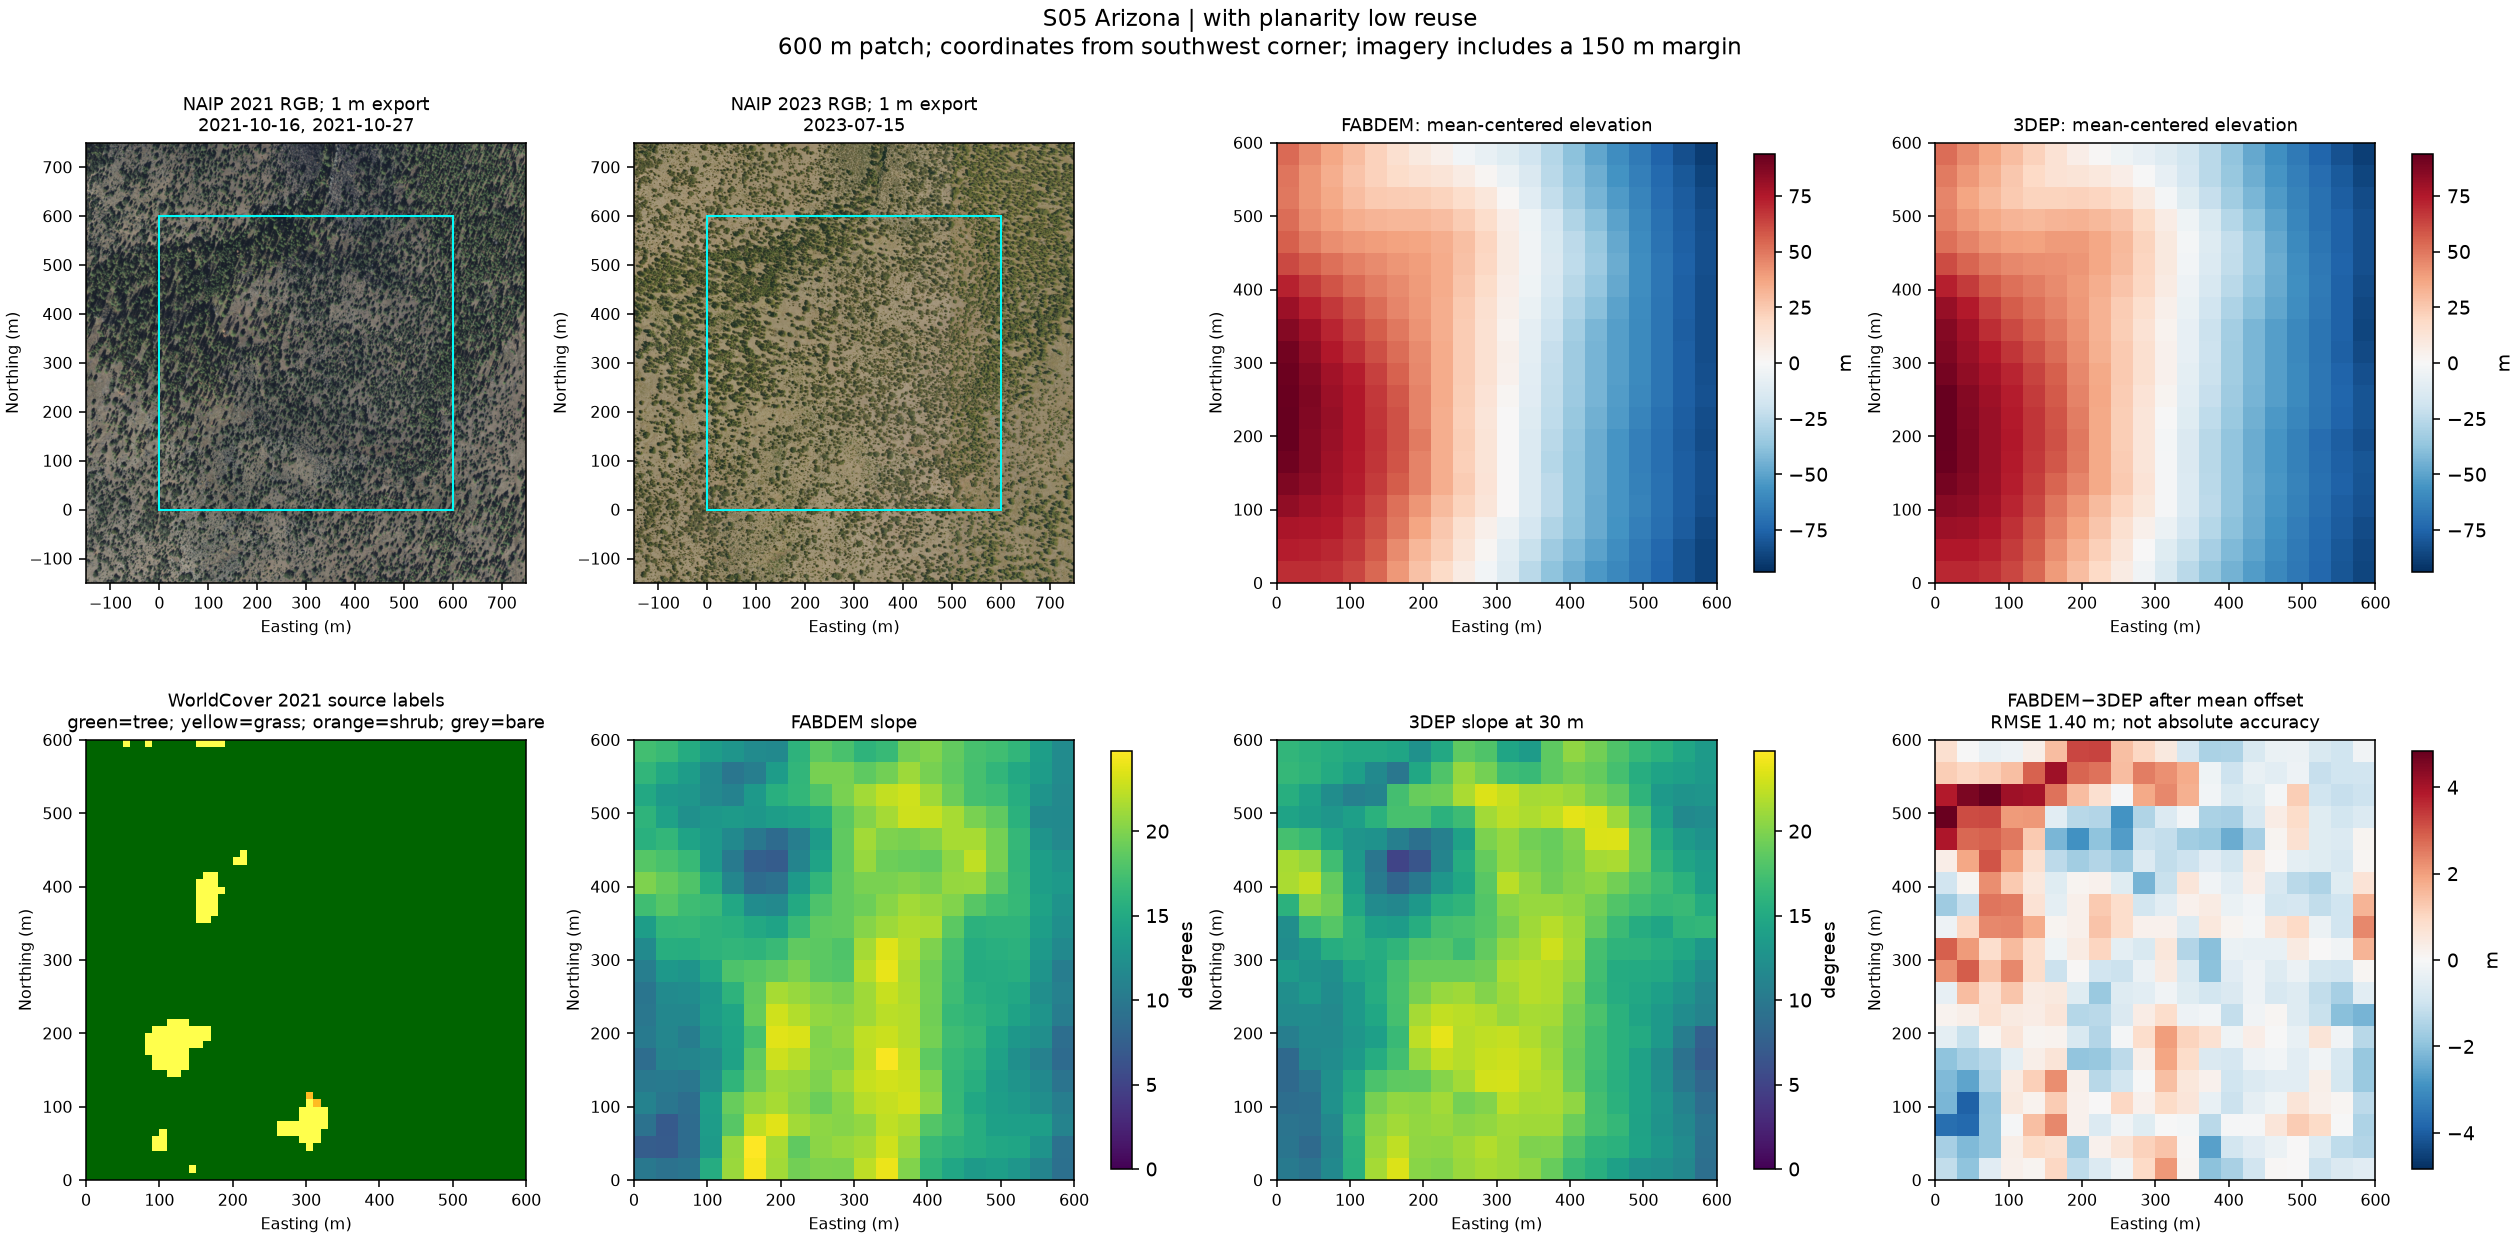

,sample_id,mean_offset_m,offset_removed_rmse_m,fabdem_plane_residual_fraction,reference_plane_residual_fraction
0,S01,0.127235,0.727229,0.129085,0.131407
1,S02,-3.241778,2.690302,0.147084,0.158025
2,S03,-0.717887,0.557664,0.190233,0.195196
3,S04,2.651584,3.537944,0.084784,0.110469
4,S05,-0.243069,1.396836,0.200614,0.210488


,sample_id,scenario,original_matched_queries,retained,retained_pct
0,S01,baseline,128,123,96.093750
1,S01,with_planarity,127,115,90.551181
2,S02,baseline,91,83,91.208791
3,S02,with_planarity,65,40,61.538462
4,S03,baseline,1,1,100.000000
5,S04,baseline,38,34,89.473684
6,S04,with_planarity,114,96,84.210526
7,S05,baseline,4,4,100.000000
8,S05,with_planarity,1,1,100.000000


In [9]:
for row in sample.loc[sample['region'] == 'northern_arizona'].to_dict('records'):
    sid = row['sample_id']
    fab, transform, crs = patch(row, 'elevation_m')
    fab_slope, _, _ = patch(row, 'slope_deg')
    fab_sd, _, _ = patch(row, 'local_elevation_std_m')
    original = {**measure_patch(fab, fab_slope, fab_sd), **measure_planarity(fab)}
    reference_path = RAW / arcgis_records[(sid, '3dep')]['path']
    reference_halo = np.full((30, 30), np.nan, dtype='float64')
    halo_transform = from_origin(row['xmin'] - 150, row['ymax'] + 150, 30, 30)
    with rasterio.open(reference_path) as src:
        assert src.crs == crs and src.shape == (900, 900) and src.res == (1., 1.)
        reproject(rasterio.band(src, 1), reference_halo, src_transform=src.transform, src_crs=src.crs,
                  dst_transform=halo_transform, dst_crs=crs, src_nodata=src.nodata, dst_nodata=np.nan, resampling=Resampling.average)
    assert np.isfinite(reference_halo).all(), f'Incomplete reference: {sid}'
    reference = reference_halo[5:25, 5:25]
    features = terrain(reference_halo, 30, 11)
    ref_slope = features['slope_deg'][5:25, 5:25]
    ref_sd = features['local_elevation_std_m'][5:25, 5:25]
    measured = {**measure_patch(reference, ref_slope, ref_sd), **measure_planarity(reference)}
    reference_features[sid] = dict(measured)
    difference = compare_elevation_surfaces(reference, fab)
    result = {'sample_id': sid, 'candidate_id': row['candidate_id'], **difference,
              **{f'fabdem_{key}': value for key, value in original.items()},
              **{f'reference_{key}': value for key, value in measured.items()}}
    terrain_rows.append(result)
    for name, values in [('reference_halo_30m', reference_halo), ('reference_elevation_m', reference),
                         ('reference_slope_deg', ref_slope), ('reference_local_sd_m', ref_sd)]:
        grid = Grid(crs, halo_transform if values.shape == (30, 30) else transform, values.shape[1], values.shape[0])
        write_raster(OUT / f'{sid}_{name}.tif', values, grid, 'degrees' if 'slope' in name else 'm', source=reference_path.name)
    # Recheck only the original successful query assignments to this selected patch.
    for scenario, prefix in [('baseline', 'b'), ('with_planarity', 'p')]:
        assigned = previous_pairs.loc[(previous_pairs['population'] == 'image_supported') & (previous_pairs['size_m'] == 600)
            & (previous_pairs['earth_site'] == 'northern_arizona') & (previous_pairs['policy'] == 'no_bare_requirement')
            & (previous_pairs[f'{prefix}_candidate_id'] == row['candidate_id']) & (previous_pairs[f'{prefix}_score'] <= 1)]
        assert len(assigned) == row[f'{scenario}_query_uses']
        for assignment in assigned.to_dict('records'):
            query = lunar_lookup.loc[assignment['query_id'], FEATURES].to_numpy(dtype=float)
            scores = terrain_discrepancies(query, np.array([[measured[name] for name in FEATURES]]))
            sensitivity_rows.append({'sample_id': sid, 'candidate_id': row['candidate_id'], 'query_id': assignment['query_id'],
                                     'scenario': scenario, 'original_score': assignment[f'{prefix}_score'],
                                     'reference_score': float(scores[scenario][0]), 'remains_in_band': bool(scores[scenario][0] <= 1)})
    fig, axes = plt.subplots(2, 4, figsize=(18, 9), constrained_layout=True)
    fig.suptitle(f"{sid} Arizona | {row['selection_reason'].replace('_', ' ').replace(';', '; ')}\n600 m patch; coordinates from southwest corner; imagery includes a 150 m margin", fontsize=12)
    for ax, year in zip(axes[0, :2], [2021, 2023], strict=True):
        record = arcgis_records[(sid, f'naip{year}')]
        with rasterio.open(RAW / record['path']) as src:
            rgb = np.moveaxis(src.read([1, 2, 3]), 0, 2)
        ax.imshow(rgb, extent=(-150, 750, -150, 750))
        ax.add_patch(Rectangle((0, 0), 600, 600, fill=False, edgecolor='cyan', linewidth=1))
        dates = sources.loc[(sources['sample_id'] == sid) & (sources['source'] == f'naip{year}'), 'acquisition_dates'].iloc[0]
        dates = ', '.join(f'{value[:4]}-{value[4:6]}-{value[6:]}' for value in dates.split(';'))
        if len(dates) > 25:
            dates = dates.replace(', ', '\n')
        ax.set_title(f'NAIP {year} RGB; 1 m export\n{dates}', fontsize=9)
    centered_fab, centered_ref = fab - fab.mean(), reference - reference.mean()
    limit = max(float(np.abs(centered_fab).max()), float(np.abs(centered_ref).max()))
    for ax, values, title in [(axes[0, 2], centered_fab, 'FABDEM: mean-centered elevation'), (axes[0, 3], centered_ref, '3DEP: mean-centered elevation')]:
        artist = ax.imshow(values, extent=(0, 600, 0, 600), cmap='RdBu_r', vmin=-limit, vmax=limit)
        ax.set_title(title, fontsize=9)
        fig.colorbar(artist, ax=ax, label='m', shrink=.8)
    wc = worldcover_display(row)
    axes[1, 0].imshow(np.searchsorted(CLASS_CODES, wc), extent=(0, 600, 0, 600), cmap=class_cmap, vmin=0, vmax=11, interpolation='nearest')
    axes[1, 0].set_title('WorldCover 2021 source labels\ngreen=tree; yellow=grass; orange=shrub; grey=bare', fontsize=9)
    slope_limit = max(float(fab_slope.max()), float(ref_slope.max()))
    for ax, values, title in [(axes[1, 1], fab_slope, 'FABDEM slope'), (axes[1, 2], ref_slope, '3DEP slope at 30 m')]:
        artist = ax.imshow(values, extent=(0, 600, 0, 600), cmap='viridis', vmin=0, vmax=slope_limit)
        ax.set_title(title, fontsize=9)
        fig.colorbar(artist, ax=ax, label='degrees', shrink=.8)
    delta = (fab - reference) - difference['mean_offset_m']
    delta_limit = max(float(np.abs(delta).max()), 1)
    artist = axes[1, 3].imshow(delta, extent=(0, 600, 0, 600), cmap='RdBu_r', vmin=-delta_limit, vmax=delta_limit)
    axes[1, 3].set_title(f"FABDEM−3DEP after mean offset\nRMSE {difference['offset_removed_rmse_m']:.2f} m; not absolute accuracy", fontsize=9)
    fig.colorbar(artist, ax=axes[1, 3], label='m', shrink=.8)
    for ax in axes.flat:
        ax.set_xlabel('Easting (m)', fontsize=8)
        ax.set_ylabel('Northing (m)', fontsize=8)
        ax.tick_params(labelsize=8)
    save_figure(fig, f'{sid}_source_comparison')
terrain_table = pd.DataFrame(terrain_rows)
terrain_table.to_csv(OUT / 'terrain_comparison.csv', index=False)
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT / 'assigned_query_sensitivity.csv', index=False)
sensitivity_summary = pd.DataFrame(sensitivity.groupby(['sample_id', 'scenario'], as_index=False).agg(original_matched_queries=('query_id', 'size'), retained=('remains_in_band', 'sum')))
sensitivity_summary['retained_pct'] = 100 * sensitivity_summary['retained'] / sensitivity_summary['original_matched_queries']
sensitivity_summary.to_csv(OUT / 'assigned_query_summary.csv', index=False)
display(terrain_table[['sample_id', 'mean_offset_m', 'offset_removed_rmse_m', 'fabdem_plane_residual_fraction', 'reference_plane_residual_fraction']])
display(sensitivity_summary)

# Atacama and Wadi: separate optical observations

Landsat30 m imagery can show broad surface patterns. It cannot establish
canopy-free elevations, small vegetation patches, obstacles or access. QA was
checked on native pixel centers inside each patch. Display resampling adds no
resolution. A source-class rendering remains dependent WorldCover evidence.

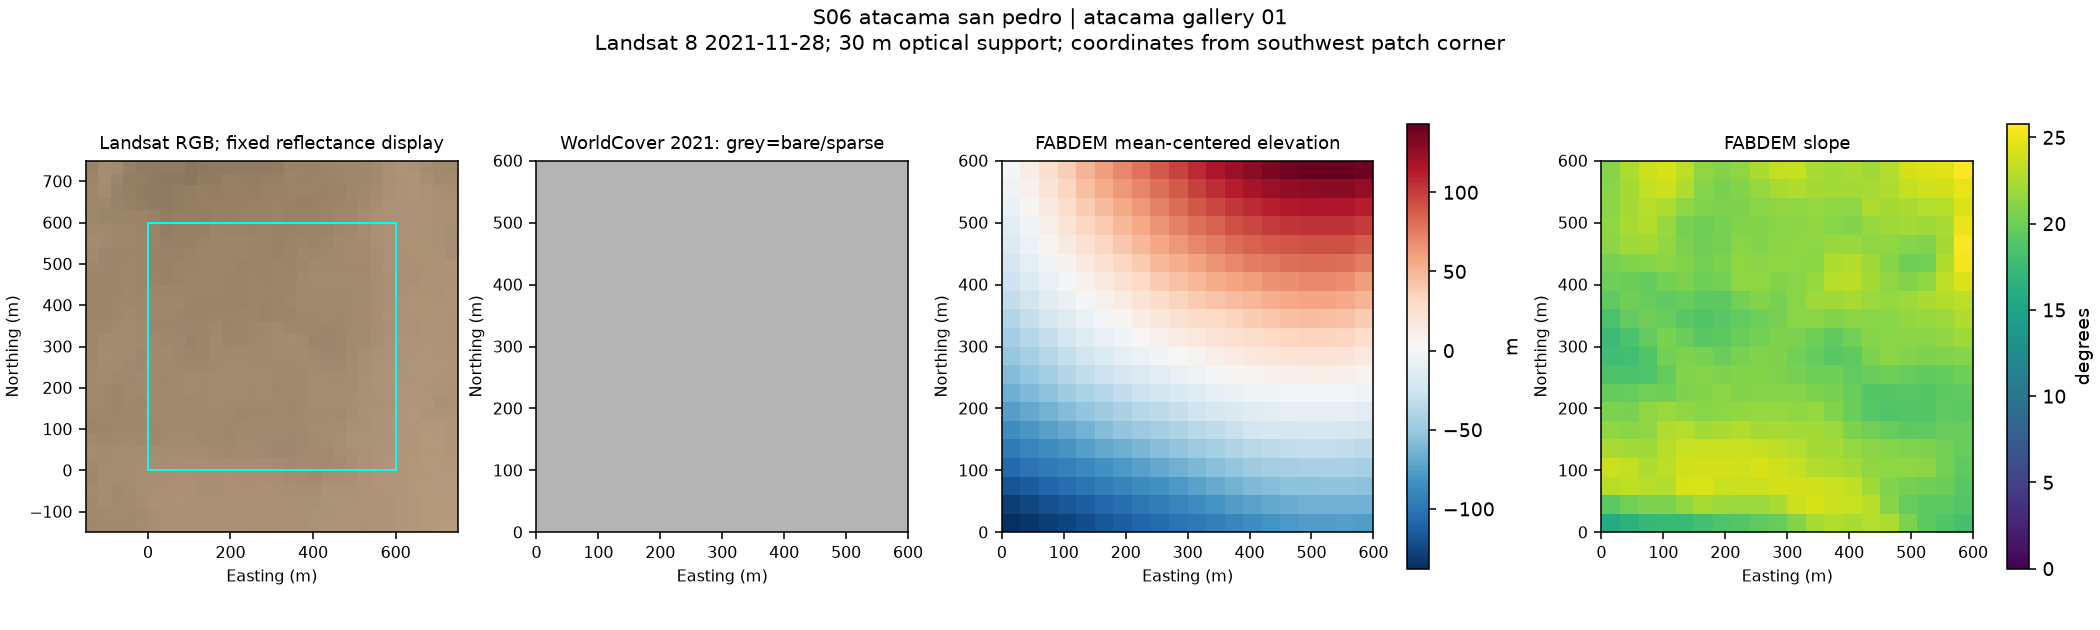

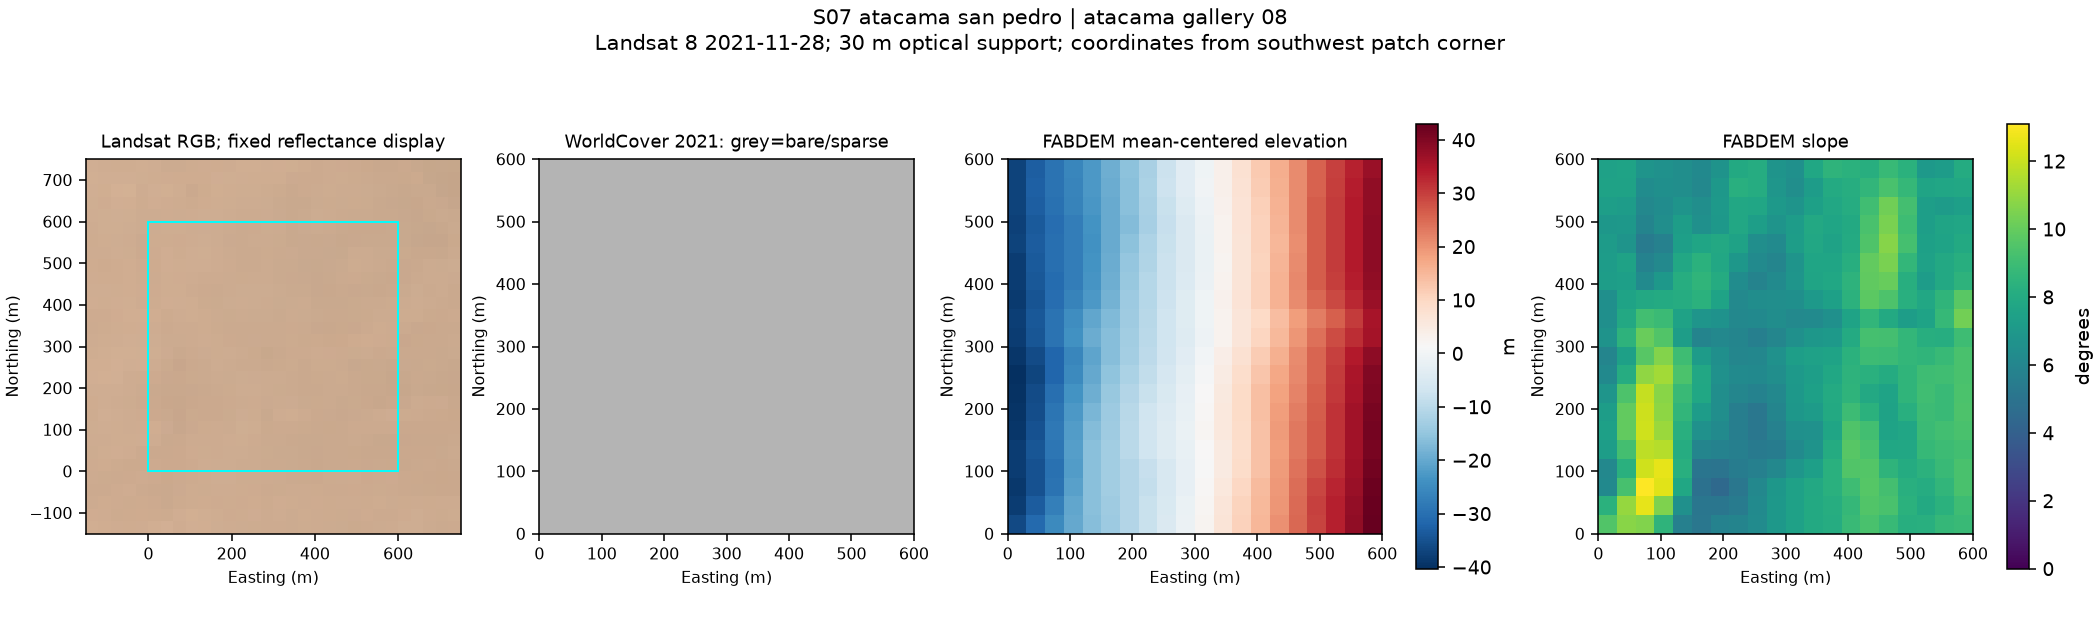

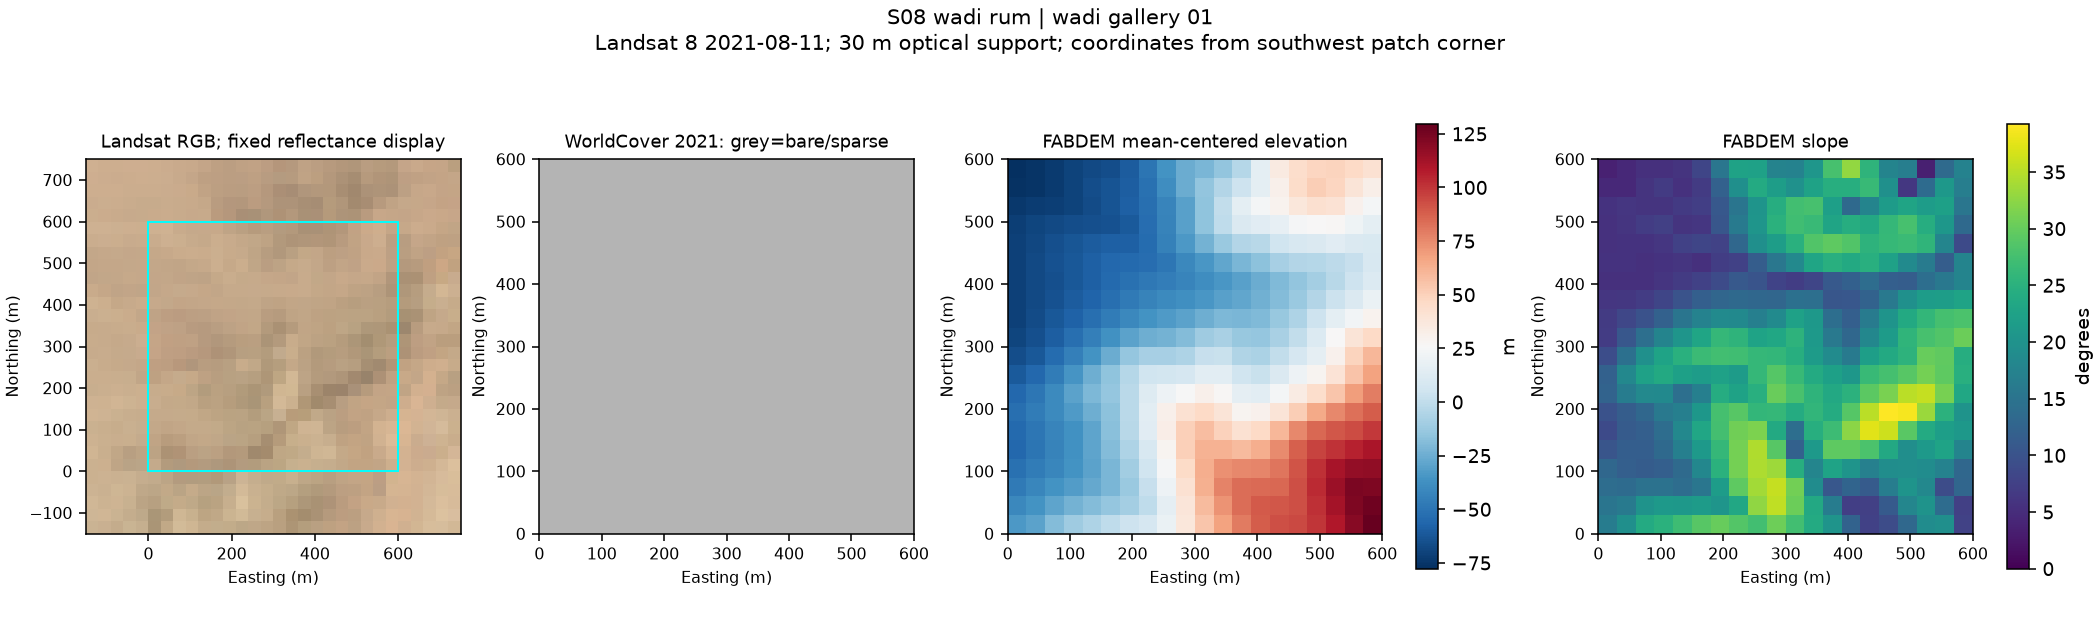

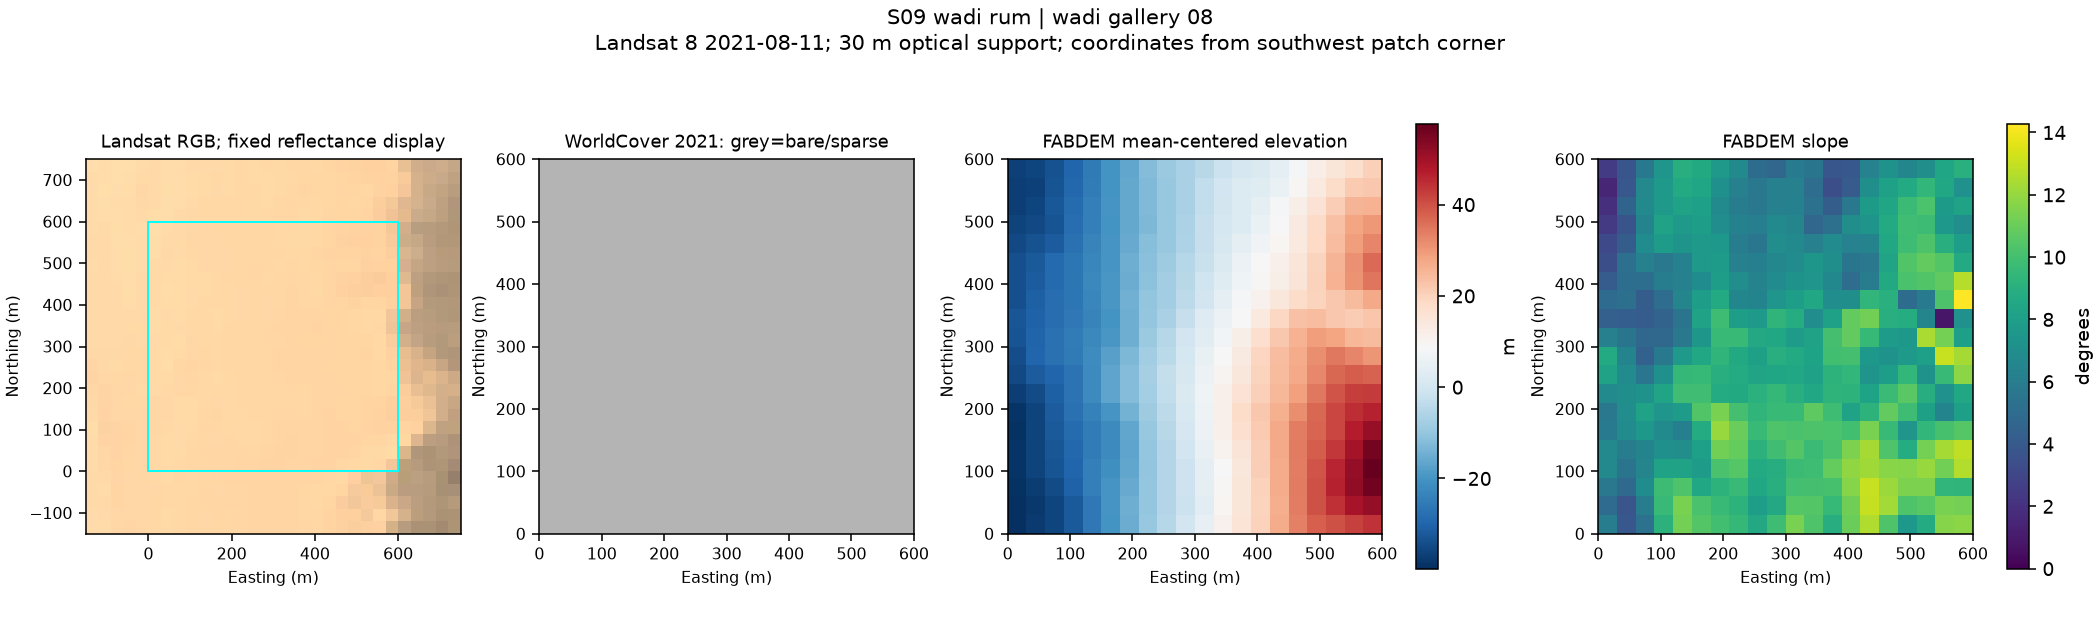

,sample_id,status,scene,date,patch_pixels,rejected_pixels,context_aerosol_code_counts
0,S06,acquired,LC08_L2SP_233076_20211128_02_T1,2021-11-28T14:31:14.497857Z,400,0,"{""64"": 5, ""66"": 105, ""96"": 851}"
1,S07,acquired,LC08_L2SP_233076_20211128_02_T1,2021-11-28T14:31:14.497857Z,400,0,"{""66"": 110, ""96"": 851}"
2,S08,acquired,LC08_L2SP_174039_20210811_02_T1,2021-08-11T08:11:37.537878Z,400,0,"{""66"": 87, ""96"": 695, ""130"": 23, ""160"": 156}"
3,S09,acquired,LC08_L2SP_174039_20210811_02_T1,2021-08-11T08:11:37.537878Z,400,0,"{""66"": 100, ""96"": 861}"


In [10]:
optical_rows = []
for row in sample.loc[sample['region'] != 'northern_arizona'].to_dict('records'):
    sid = row['sample_id']
    if sid not in landsat_records:
        optical_rows.append({'sample_id': sid, 'status': 'no_scene_passed_bounded_qa'})
        continue
    record = landsat_records[sid]
    folder = RAW / record['folder']
    cube = np.full((3, 30, 30), np.nan, dtype='float32')
    target_transform = from_origin(row['xmin'] - 150, row['ymax'] + 150, 30, 30)
    for band_index, key in enumerate(['red', 'green', 'blue']):
        asset = record['assets'][key]
        with rasterio.open(folder / asset['path']) as src:
            reproject(rasterio.band(src, 1), cube[band_index], src_transform=src.transform, src_crs=src.crs,
                      dst_transform=target_transform, dst_crs=row['epsg'], src_nodata=0, dst_nodata=np.nan, resampling=Resampling.nearest)
    reflectance = cube * .0000275 - .2
    rgb = np.moveaxis(np.clip(reflectance / .4, 0, 1)**(1 / 2.2), 0, 2)
    with rasterio.open(folder / record['assets']['qa_aerosol']['path']) as src:
        aerosol_values, aerosol_counts = np.unique(src.read(1), return_counts=True)
    optical_rows.append({'sample_id': sid, 'status': 'acquired', 'scene': record['item_id'], 'date': record['date'],
                         **record['qa'], 'context_aerosol_code_counts': json.dumps(dict(zip(map(int, aerosol_values), map(int, aerosol_counts), strict=True)))})
    fab, _, _ = patch(row, 'elevation_m')
    slope, _, _ = patch(row, 'slope_deg')
    fig, axes = plt.subplots(1, 4, figsize=(15, 4.5), constrained_layout=True)
    fig.suptitle(f"{sid} {row['region'].replace('_', ' ')} | {row['selection_reason'].replace('_', ' ')}\nLandsat 8 {record['date'][:10]}; 30 m optical support; coordinates from southwest patch corner", fontsize=11)
    axes[0].imshow(rgb, extent=(-150, 750, -150, 750), interpolation='nearest')
    axes[0].add_patch(Rectangle((0, 0), 600, 600, fill=False, edgecolor='cyan', linewidth=1))
    axes[0].set_title('Landsat RGB; fixed reflectance display', fontsize=9)
    wc = worldcover_display(row)
    axes[1].imshow(np.searchsorted(CLASS_CODES, wc), extent=(0, 600, 0, 600), cmap=class_cmap, vmin=0, vmax=11, interpolation='nearest')
    axes[1].set_title('WorldCover 2021: grey=bare/sparse', fontsize=9)
    artist = axes[2].imshow(fab - fab.mean(), extent=(0, 600, 0, 600), cmap='RdBu_r')
    axes[2].set_title('FABDEM mean-centered elevation', fontsize=9)
    fig.colorbar(artist, ax=axes[2], label='m', shrink=.8)
    artist = axes[3].imshow(slope, extent=(0, 600, 0, 600), cmap='viridis', vmin=0)
    axes[3].set_title('FABDEM slope', fontsize=9)
    fig.colorbar(artist, ax=axes[3], label='degrees', shrink=.8)
    for ax in axes:
        ax.set_xlabel('Easting (m)', fontsize=8)
        ax.set_ylabel('Northing (m)', fontsize=8)
        ax.tick_params(labelsize=8)
    save_figure(fig, f'{sid}_source_comparison')
optical = pd.DataFrame(optical_rows)
optical.to_csv(OUT / 'optical_quality.csv', index=False)
display(optical)

# Findings and evidence limits

Numerical comparisons are a source-sensitivity check on the fixed assignments,
not a collection-wide reranking or an analog-accuracy estimate. Repeated lunar
queries and five selected Arizona patches are not independent replication.
Visual observations are recorded separately after inspection of these figures.

In [11]:
# Read the Markdown notes below for the standalone report export.
report_notebook = json.loads((ROOT / 'notebooks/exploration/24_candidate_source_check_eda.ipynb').read_text(encoding="utf-8"))
report_notes = {entry["metadata"]["report_section"]: "".join(entry["source"])
                for entry in report_notebook["cells"]
                if entry["cell_type"] == "markdown" and "report_section" in entry["metadata"]}
observations = pd.DataFrame([
    {'sample_id': 'S01', 'observation': 'Numerous crown-like objects and shadows in the 2021 image, with a greener ground appearance and different shadow pattern in 2023. Woody cover is visible; the pair does not isolate physical cover change from season and illumination.'},
    {'sample_id': 'S02', 'observation': 'Dense crown texture is visible across most of the patch in both years, with small openings near the southwest edge. The broad inclined ground form is retained in the reference DEM.'},
    {'sample_id': 'S03', 'observation': 'An open pale surface with channels or rock edges is visible in both years, without dense tree crowns. WorldCover contains grass, shrub and bare labels. RGB appearance alone cannot resolve dry grass versus exposed ground or establish a vegetation fraction.'},
    {'sample_id': 'S04', 'observation': 'Crown texture and low vegetation or open gaps are visible in both years. Color and shadows differ with the acquired dates. The reference retains the broad slope but shows local differences and a larger plane-residual fraction.'},
    {'sample_id': 'S05', 'observation': 'Scattered woody crowns and intervening open ground are visible in both years. This is not a uniformly exposed surface despite its broadly inclined estimated ground form.'},
    {'sample_id': 'S06', 'observation': 'The Landsat patch appears mostly uniform brown with weak broad tonal variation. At 30 m this is compatible with an exposed-surface interpretation but does not verify every bare/sparse class label or rule out small vegetation.'},
    {'sample_id': 'S07', 'observation': 'The Landsat patch appears mostly uniform pale brown. Fine cover, obstacles and ground elevation remain unresolved at this optical support.'},
    {'sample_id': 'S08', 'observation': 'Broad tonal bands and a darker diagonal feature are visible in Landsat beside the more varied FABDEM slope pattern. This offers spatial context for the failing pair, not an independent validation of the DEM geometry.'},
    {'sample_id': 'S09', 'observation': 'A bright, relatively uniform patch borders darker material near the eastern context edge. The image offers broad surface context for the matched example; it does not establish analog relevance or elevation accuracy.'},
])
assert observations['sample_id'].tolist() == sample['sample_id'].tolist()
observations.to_csv(OUT / 'visual_observations.csv', index=False)
lines = [
    '# Bounded candidate source check',
    '',
    'Nine development patches follow the [predeclared design](../../../../notebooks/exploration/24_candidate_source_check_eda.ipynb). Moon and Earth only. No screen, physical band or reserve-role change.',
    *report_notes['narrative-04a6c4e3-1'].split('\n'),
]
for row in terrain_table.to_dict('records'):
    lines.append(f"| {row['sample_id']} | {row['mean_offset_m']:.2f} | {row['offset_removed_rmse_m']:.2f} | {row['fabdem_slope_median_deg']:.2f}/{row['reference_slope_median_deg']:.2f} | {row['fabdem_central_relief_m']:.1f}/{row['reference_central_relief_m']:.1f} | {row['fabdem_plane_residual_fraction']:.3f}/{row['reference_plane_residual_fraction']:.3f} |")
lines += [
    *report_notes['narrative-04a6c4e3-2'].split('\n'),
]
for row in sensitivity_summary.to_dict('records'):
    lines.append(f"| {row['sample_id']} | {row['scenario']} | {row['original_matched_queries']} | {row['retained']} | {row['retained_pct']:.1f}% |")
lines += ['', '## Acquired evidence', '',
          'All five Arizona patches have dated NAIP 2021 and NAIP 2023 observations and complete source-locked 3DEP exports. The [inventory](source_inventory.csv) records source names, IDs, acquisition ranges and endpoints. NAIP is displayed as native U8 RGB at 1 m export spacing; dates and season differ. WorldCover maps reuse the original classification, while NAIP is a separate aerial observation.', '',
          'Atacama and Wadi use the first scene in the 2021 ordering whose two patches pass QA, after requiring full context-footprint coverage. The [acquisition adjustments](../../../reference/source-check-research-20261029/ACQUISITION_ADJUSTMENTS.md) explain this geometric refinement after initial Wadi scenes missed a sample, the HTTP429 retry and unavailable optional MTL JSON assets. The [optical QA table](optical_quality.csv) records actual scene/date and native-patch pixel checks; attempted scenes and original asset values are in the pinned raw snapshot. Landsat reflectance uses DN × 0.0000275 − 0.2; fixed display range 0–0.4 and gamma 1/2.2. Source imagery has 30 m support; no independent ground-elevation reference was acquired for these four patches.', '',
          'Provider properties, QA definitions, datum issues and source ancestry are cited in the [source research](../../../reference/source-check-research-20261029/SOURCES.md). Possible overlap between older lidar sources and FABDEM model-development data remains unresolved. Separately acquired observations are not automatically independent model validation. Dates after the original paper establish timing, not local exclusion from every later product version.', '',
          '## Inspection figures', '']
for sid in sample['sample_id']:
    if (OUT / f'{sid}_source_comparison.png').exists():
        lines.append(f'- [{sid} source comparison]({sid}_source_comparison.png).')
lines += [
    *report_notes['narrative-04a6c4e3-3'].split('\n'),
]
for row in observations.to_dict('records'):
    lines.append(f"- **{row['sample_id']}:** {row['observation']}")
lines += [
    *report_notes['narrative-04a6c4e3-4'].split('\n'),
    'Keep the baseline and alternative screens separate. The [terrain handoff](../../../../outline.md) summarizes the usable populations, policy tradeoff and remaining limitations. Continue terrain EDA only for a specific decision-relevant finding; the next broad branch is native-support environmental coverage, variation and joint availability. Task-specific relevance, geographic evaluation grouping and independent assessment are still needed before model validation.',
    '',
    '## Artifacts',
    '',
    '- [Sample](sample.csv), [terrain comparison](terrain_comparison.csv), [source inventory](source_inventory.csv).',
    '- [Per-assignment sensitivity](assigned_query_sensitivity.csv), [sensitivity summary](assigned_query_summary.csv).',
    '- [Optical QA](optical_quality.csv), [provenance](provenance.json).',
    '',
]
lines.insert(-1, '- [Manual visual observations](visual_observations.csv).')
(OUT / 'REPORT.md').write_text('\n'.join(lines), encoding='utf-8')
provenance.update(status='publishing', inputs=inputs, outputs={p.name: file_hash(p) for p in OUT.iterdir() if p.is_file() and p.name != 'provenance.json'})
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
display(Markdown((OUT / 'REPORT.md').read_text(encoding='utf-8')))
print('Completed:', OUT)

# Bounded candidate source check

Nine development patches follow the [predeclared design](../../../../notebooks/exploration/24_candidate_source_check_eda.ipynb). Moon and Earth only. No screen, physical band or reserve-role change.

## Arizona ground-form comparison

Reference elevations are 1 m USGS service exports aggregated to the existing 30 m grid with a 150 m halo. Sources are locked to the finest primary resolution and latest acquisition-start date. Full finite support is required. No horizontal shift is fitted. NAVD88 versus EGM2008 remains unresolved: a constant mean offset is removed for the discrepancy below, which is **not absolute elevation accuracy**.

| Patch | Mean FABDEM−reference offset(m) | Offset-removed RMSE(m) | FABDEM/reference median slope(deg) | FABDEM/reference central relief(m) | FABDEM/reference plane fraction |
| --- | ---: | ---: | ---: | ---: | ---: |
| S01 | 0.13 | 0.73 | 17.70/17.51 | 171.2/171.6 | 0.129/0.131 |
| S02 | -3.24 | 2.69 | 19.09/18.91 | 177.8/177.3 | 0.147/0.158 |
| S03 | -0.72 | 0.56 | 9.93/9.94 | 86.0/86.2 | 0.190/0.195 |
| S04 | 2.65 | 3.54 | 20.88/21.21 | 201.1/198.9 | 0.085/0.110 |
| S05 | -0.24 | 1.40 | 16.46/16.79 | 161.6/161.2 | 0.201/0.210 |

## Sensitivity of original successful assignments

Recompute the same bands for the same lunar queries and selected Earth locations using reference-derived descriptors. No alternative candidate search is performed. Lost assignments could still have another counterpart elsewhere; these counts are not revised regional coverage.

| Patch | Scenario | Original assigned matches | Still within bands | Retained |
| --- | --- | ---: | ---: | ---: |
| S01 | baseline | 128 | 123 | 96.1% |
| S01 | with_planarity | 127 | 115 | 90.6% |
| S02 | baseline | 91 | 83 | 91.2% |
| S02 | with_planarity | 65 | 40 | 61.5% |
| S03 | baseline | 1 | 1 | 100.0% |
| S04 | baseline | 38 | 34 | 89.5% |
| S04 | with_planarity | 114 | 96 | 84.2% |
| S05 | baseline | 4 | 4 | 100.0% |
| S05 | with_planarity | 1 | 1 | 100.0% |

## Acquired evidence

All five Arizona patches have dated NAIP 2021 and NAIP 2023 observations and complete source-locked 3DEP exports. The [inventory](source_inventory.csv) records source names, IDs, acquisition ranges and endpoints. NAIP is displayed as native U8 RGB at 1 m export spacing; dates and season differ. WorldCover maps reuse the original classification, while NAIP is a separate aerial observation.

Atacama and Wadi use the first scene in the 2021 ordering whose two patches pass QA, after requiring full context-footprint coverage. The [acquisition adjustments](../../../reference/source-check-research-20261029/ACQUISITION_ADJUSTMENTS.md) explain this geometric refinement after initial Wadi scenes missed a sample, the HTTP429 retry and unavailable optional MTL JSON assets. The [optical QA table](optical_quality.csv) records actual scene/date and native-patch pixel checks; attempted scenes and original asset values are in the pinned raw snapshot. Landsat reflectance uses DN × 0.0000275 − 0.2; fixed display range 0–0.4 and gamma 1/2.2. Source imagery has 30 m support; no independent ground-elevation reference was acquired for these four patches.

Provider properties, QA definitions, datum issues and source ancestry are cited in the [source research](../../../reference/source-check-research-20261029/SOURCES.md). Possible overlap between older lidar sources and FABDEM model-development data remains unresolved. Separately acquired observations are not automatically independent model validation. Dates after the original paper establish timing, not local exclusion from every later product version.

## Inspection figures

- [S01 source comparison](S01_source_comparison.png).
- [S02 source comparison](S02_source_comparison.png).
- [S03 source comparison](S03_source_comparison.png).
- [S04 source comparison](S04_source_comparison.png).
- [S05 source comparison](S05_source_comparison.png).
- [S06 source comparison](S06_source_comparison.png).
- [S07 source comparison](S07_source_comparison.png).
- [S08 source comparison](S08_source_comparison.png).
- [S09 source comparison](S09_source_comparison.png).

## Qualitative visual observations

The following are manual annotations from inspection of these archived observations, not classifier outputs, blind labels or measured cover fractions.

- **S01:** Numerous crown-like objects and shadows in the 2021 image, with a greener ground appearance and different shadow pattern in 2023. Woody cover is visible; the pair does not isolate physical cover change from season and illumination.
- **S02:** Dense crown texture is visible across most of the patch in both years, with small openings near the southwest edge. The broad inclined ground form is retained in the reference DEM.
- **S03:** An open pale surface with channels or rock edges is visible in both years, without dense tree crowns. WorldCover contains grass, shrub and bare labels. RGB appearance alone cannot resolve dry grass versus exposed ground or establish a vegetation fraction.
- **S04:** Crown texture and low vegetation or open gaps are visible in both years. Color and shadows differ with the acquired dates. The reference retains the broad slope but shows local differences and a larger plane-residual fraction.
- **S05:** Scattered woody crowns and intervening open ground are visible in both years. This is not a uniformly exposed surface despite its broadly inclined estimated ground form.
- **S06:** The Landsat patch appears mostly uniform brown with weak broad tonal variation. At 30 m this is compatible with an exposed-surface interpretation but does not verify every bare/sparse class label or rule out small vegetation.
- **S07:** The Landsat patch appears mostly uniform pale brown. Fine cover, obstacles and ground elevation remain unresolved at this optical support.
- **S08:** Broad tonal bands and a darker diagonal feature are visible in Landsat beside the more varied FABDEM slope pattern. This offers spatial context for the failing pair, not an independent validation of the DEM geometry.
- **S09:** A bright, relatively uniform patch borders darker material near the eastern context edge. The image offers broad surface context for the matched example; it does not establish analog relevance or elevation accuracy.

## Interpretation boundary and next decision

The five Arizona reference surfaces corroborate broad terrain form at the checked support. Across the selected assignments, 245/262 baseline matches and 252/307 planarity-aware matches remain inside the unchanged bands. These conditional counts do not revise Arizona-wide coverage or establish analog accuracy. Four selected Arizona examples show woody cover; S03 provides an open-surface contrast but serves only one baseline query and no planarity-aware query in the original selection.

Optical evidence cannot prove ground elevation beneath canopy or practical access. Terrain agreement supports only the checked spatial form and support; terrain disagreement may include source age, smoothing, registration or model effects. Do not infer a vegetation percentage by eye or create positive/negative analog labels.

Keep the baseline and alternative screens separate. The [terrain handoff](../../../../outline.md) summarizes the usable populations, policy tradeoff and remaining limitations. Continue terrain EDA only for a specific decision-relevant finding; the next broad branch is native-support environmental coverage, variation and joint availability. Task-specific relevance, geographic evaluation grouping and independent assessment are still needed before model validation.

## Artifacts

- [Sample](sample.csv), [terrain comparison](terrain_comparison.csv), [source inventory](source_inventory.csv).
- [Per-assignment sensitivity](assigned_query_sensitivity.csv), [sensitivity summary](assigned_query_summary.csv).
- [Optical QA](optical_quality.csv), [provenance](provenance.json).
- [Manual visual observations](visual_observations.csv).


Completed: .\data\processed\analysis\source-check-20261102T143617305524Z



## Arizona ground-form comparison

Reference elevations are 1 m USGS service exports aggregated to the existing 30 m grid with a 150 m halo. Sources are locked to the finest primary resolution and latest acquisition-start date. Full finite support is required. No horizontal shift is fitted. NAVD88 versus EGM2008 remains unresolved: a constant mean offset is removed for the discrepancy below, which is **not absolute elevation accuracy**.

| Patch | Mean FABDEM−reference offset(m) | Offset-removed RMSE(m) | FABDEM/reference median slope(deg) | FABDEM/reference central relief(m) | FABDEM/reference plane fraction |
| --- | ---: | ---: | ---: | ---: | ---: |


## Sensitivity of original successful assignments

Recompute the same bands for the same lunar queries and selected Earth locations using reference-derived descriptors. No alternative candidate search is performed. Lost assignments could still have another counterpart elsewhere; these counts are not revised regional coverage.

| Patch | Scenario | Original assigned matches | Still within bands | Retained |
| --- | --- | ---: | ---: | ---: |


## Qualitative visual observations

The following are manual annotations from inspection of these archived observations, not classifier outputs, blind labels or measured cover fractions.



## Interpretation boundary and next decision

The five Arizona reference surfaces corroborate broad terrain form at the checked support. Across the selected assignments, 245/262 baseline matches and 252/307 planarity-aware matches remain inside the unchanged bands. These conditional counts do not revise Arizona-wide coverage or establish analog accuracy. Four selected Arizona examples show woody cover; S03 provides an open-surface contrast but serves only one baseline query and no planarity-aware query in the original selection.

Optical evidence cannot prove ground elevation beneath canopy or practical access. Terrain agreement supports only the checked spatial form and support; terrain disagreement may include source age, smoothing, registration or model effects. Do not infer a vegetation percentage by eye or create positive/negative analog labels.


## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [12]:
import sys

sys.path.insert(0, str(ROOT))
from notebooks.shared.analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\source-check-20261102T143617305524Z
Disposable reports: .\reports\analysis\source-check-20261102T143617305524Z
